# code_117 · Local graph attention and distant information

**Book:** section 23.3. A self-contained architecture laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_23_GUIDE.md), [run evidence](../CHAPTER_23_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_117).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2517;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2517


<a id="graph-attention-contract"></a>
 ## Can the query receive the required load?
 Generate 260 independent sixteen-member chain graphs, with 120/40/100 training/development/final graphs. Each node has a random admitted load plus root/terminal indicators. The root response is the far terminal load. A two-layer local GAT-style network cannot access that terminal fifteen hops away. Compare a small global graph transformer with shortest-path attention biases, using the same admitted node data. Both search two rates for 400 updates and restore their own development checkpoint; parameter counts differ, and this is a constructed reachability test rather than a parameter-matched ranking. A direct terminal-marker selector solves the known teaching rule exactly and is retained as a simple reference. No labels enter attention, and nonedge attention does not create a physical connection.


,model,development_MSE,final_MSE,selected_rate,best_step,parameters
0,Local GAT,0.717457,0.734212,0.005,10,145
1,Graph transformer,0.000090,0.000023,0.010,400,673


,depth,diffusion_node_variance,original_reinjection_variance
0,0,0.736118,0.736118
1,1,0.195273,0.199954
2,2,0.115020,0.139175
3,4,0.066172,0.094401
4,8,0.033154,0.069747
5,16,0.013519,0.059243
6,32,0.004864,0.056900
7,64,0.001584,0.056743
8,128,0.000258,0.056741
9,256,0.000007,0.056741


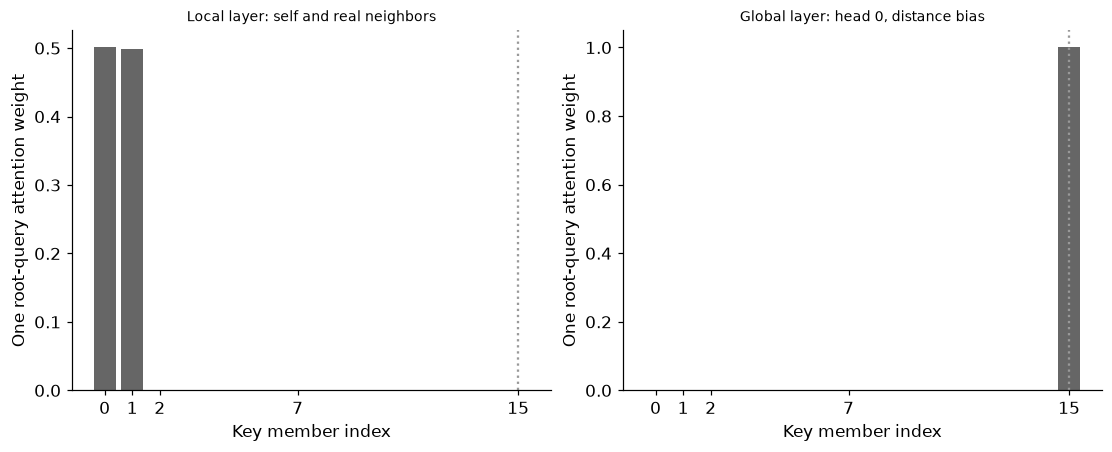

In [2]:
import copy
N=16;B=260;raw=rng.normal(size=(B,N,3));raw[:,:,1:]=0;raw[:,0,1]=1;raw[:,-1,2]=1;x=torch.tensor(raw);y=x[:,-1,0].clone();adj=torch.eye(N)
for i in range(N-1):adj[i,i+1]=adj[i+1,i]=1
distance=torch.abs(torch.arange(N)[:,None]-torch.arange(N)[None,:]);train=slice(0,120);dev=slice(120,160);final=slice(160,None)
class GATLayer(nn.Module):
    def __init__(self,incoming,outgoing):
        super().__init__();self.linear=nn.Linear(incoming,outgoing,bias=False);self.query=nn.Parameter(torch.randn(outgoing)*.1);self.key=nn.Parameter(torch.randn(outgoing)*.1);self.bias=nn.Parameter(torch.zeros(outgoing))
    def forward(self,h,a):
        z=self.linear(h);q=z@self.query;k=z@self.key;score=nn.functional.leaky_relu(q[:,:,None]+k[:,None,:],negative_slope=.2);weights=score.masked_fill(a==0,-torch.inf).softmax(-1);return weights@z+self.bias,weights
class LocalGAT(nn.Module):
    def __init__(self):super().__init__();self.first=GATLayer(3,8);self.second=GATLayer(8,8);self.head=nn.Linear(8,1)
    def forward(self,h,a,d,return_weights=False):
        h,_=self.first(h,a);h,weights=self.second(torch.relu(h),a);pred=self.head(torch.relu(h)).squeeze(-1);return (pred,weights) if return_weights else pred
class GraphTransformer(nn.Module):
    def __init__(self):
        super().__init__();self.input=nn.Linear(3,8);self.norm1=nn.LayerNorm(8);self.qkv=nn.Linear(8,24);self.project=nn.Linear(8,8);self.distance_bias=nn.Embedding(16,2);self.norm2=nn.LayerNorm(8);self.ff=nn.Sequential(nn.Linear(8,16),nn.GELU(),nn.Linear(16,8));self.head=nn.Linear(8,1)
    def forward(self,h,a,d,return_weights=False):
        h=self.input(h);z=self.norm1(h);q,k,v=self.qkv(z).chunk(3,dim=-1);batch,n,_=z.shape
        def heads(z):return z.reshape(batch,n,2,4).transpose(1,2)
        q,k,v=map(heads,[q,k,v]);bias=self.distance_bias(d).permute(2,0,1);weights=(q@k.transpose(-1,-2)/2+bias).softmax(-1);mix=(weights@v).transpose(1,2).reshape(batch,n,8);h=h+self.project(mix);h=h+self.ff(self.norm2(h));pred=self.head(h).squeeze(-1);return (pred,weights) if return_weights else pred
rows=[];candidates=[];fitted={};constructors={'Local GAT':LocalGAT,'Graph transformer':GraphTransformer}
for name,constructor in constructors.items():
    family_best=np.inf
    for rate in [.005,.01]:
        torch.manual_seed(SEED);model=constructor();opt=torch.optim.AdamW(model.parameters(),lr=rate,weight_decay=.001);best=np.inf
        for step in range(1,401):
            opt.zero_grad();pred=model(x[train],adj,distance)[:,0];loss=torch.mean((pred-y[train])**2);loss.backward();opt.step()
            if step%10==0:
                with torch.no_grad():score=float(torch.mean((model(x[dev],adj,distance)[:,0]-y[dev])**2))
                if score<best:best=score;state=copy.deepcopy(model.state_dict());best_step=step
        candidates.append({'model':name,'rate':rate,'development_MSE':best,'best_step':best_step})
        if best<family_best:family_best=best;chosen=(rate,best_step,state)
    rate,best_step,state=chosen;model.load_state_dict(state);model.eval();fitted[name]=model
    with torch.no_grad():prediction=model(x[final],adj,distance)[:,0];score=float(torch.mean((prediction-y[final])**2))
    rows.append({'model':name,'development_MSE':family_best,'final_MSE':score,'selected_rate':rate,'best_step':best_step,'parameters':sum(p.numel() for p in model.parameters())})
probe=x[160:161].clone().requires_grad_(True);root=fitted['Local GAT'](probe,adj,distance)[0,0];local_gradient=torch.autograd.grad(root,probe)[0];assert torch.max(torch.abs(local_gradient[:,3:]))==0
probe2=x[160:161].clone().requires_grad_(True);root2=fitted['Graph transformer'](probe2,adj,distance)[0,0];global_gradient=torch.autograd.grad(root2,probe2)[0];assert torch.abs(global_gradient[0,-1,0])>1e-8
permutation=torch.tensor(rng.permutation(N));permutation_errors={}
with torch.no_grad():
    for name,model in fitted.items():
        original=model(x[160:161],adj,distance);changed=model(x[160:161,permutation],adj[permutation][:,permutation],distance[permutation][:,permutation]);torch.testing.assert_close(changed,original[:,permutation],atol=1e-11,rtol=1e-11);permutation_errors[name]=float(torch.max(torch.abs(changed-original[:,permutation])))
    local_prediction,local_weights=fitted['Local GAT'](x[160:161],adj,distance,True);global_prediction,global_weights=fitted['Graph transformer'](x[160:161],adj,distance,True)
assert torch.max(local_weights.masked_select((adj==0)[None]))==0
known_rule=(x[:,:,0]*x[:,:,2]).sum(1);torch.testing.assert_close(known_rule,y)
# Repeated fixed mean diffusion illustrates smoothing, not a fitted network theorem.
transition=adj/adj.sum(-1,keepdim=True);initial=torch.tensor(rng.normal(size=(N,4)));current=initial.clone();reinject=initial.clone();mixing=[]
for depth in range(257):
    if depth in [0,1,2,4,8,16,32,64,128,256]:mixing.append({'depth':depth,'diffusion_node_variance':float(current.var(0,unbiased=False).mean()),'original_reinjection_variance':float(reinject.var(0,unbiased=False).mean())})
    current=transition@current;reinject=.1*initial+.9*(transition@reinject)
bottleneck=[]
for depth in range(1,9):
    leaves=torch.ones(2**depth,requires_grad=True);value=leaves
    for layer in range(depth):value=value.reshape(-1,2).mean(1)
    gradient=torch.autograd.grad(value.sum(),leaves)[0];torch.testing.assert_close(gradient,torch.full_like(gradient,2.**(-depth)));bottleneck.append({'binary_tree_depth':depth,'leaf_count':len(leaves),'one_leaf_derivative':float(gradient[0])})
RESULTS.update(comparisons=rows,candidates=candidates,split_graphs=[120,40,100],chain_nodes=16,terminal_distance=15,known_marker_rule_final_MSE=0.,local_outside_two_hops_derivative_max=float(torch.max(torch.abs(local_gradient[:,3:]))),global_terminal_load_derivative=float(global_gradient[0,-1,0]),permutation_max_errors=permutation_errors,mixing_fixture=mixing,mean_tree_bottleneck=bottleneck);display(pd.DataFrame(rows));display(pd.DataFrame(mixing))
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].bar(np.arange(N),local_weights[0,0].numpy(),color='.4');axes[1].bar(np.arange(N),global_weights[0,0,0].numpy(),color='.4')
for ax in axes:ax.axvline(15,color='.6',linestyle=':');ax.set(xlabel='Key member index',ylabel='One root-query attention weight',xticks=[0,1,2,7,15])
axes[0].set_title('Local layer: self and real neighbors');axes[1].set_title('Global layer: head 0, distance bias');plt.show()


<a id="graph-bottleneck-limits"></a>
 ## Access, mixing and compression are distinct
 Two local layers limit root derivatives to two hops even if attention scores are learned. The graph transformer's structural-distance bias and global access are explicit additional architecture choices, not new measured physical edges. Renumbering requires permuting both adjacency and distance encodings. Attention weights alone are not explanations. The separate fixed diffusion fixture can make node representations similar (oversmoothing). Reinjecting original features retains distinctions in that fixture. In a binary mean-aggregation tree, one leaf's derivative is 2 raised to minus depth as growing inputs compress into one scalar; this illustrates a bottleneck (oversquashing) without establishing a universal trained-network bound. These effects need different diagnoses and do not imply that adding depth or global attention always improves operational accuracy.


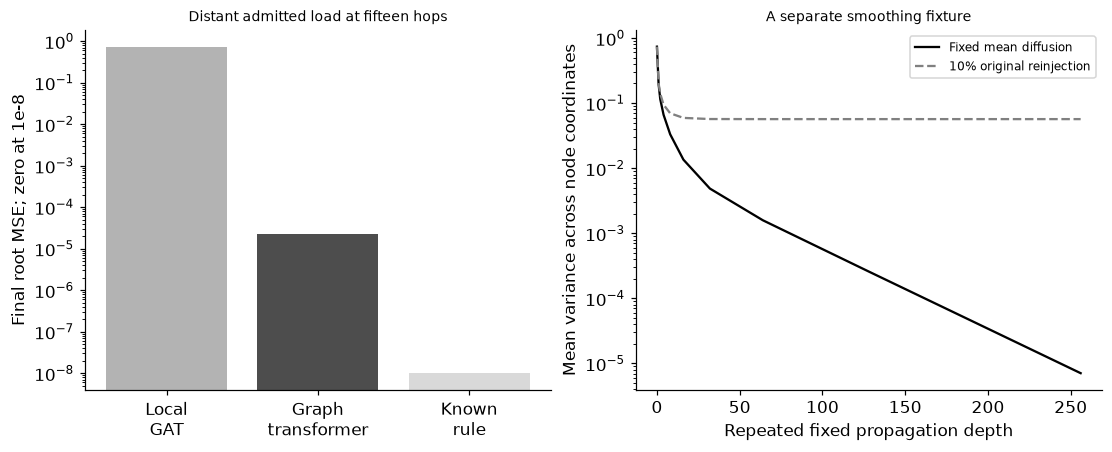

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));values=[r['final_MSE'] for r in rows]+[0.];axes[0].bar(range(3),np.maximum(values,1e-8),color=['.7','.3','.85']);axes[0].set(yscale='log',xticks=range(3),xticklabels=['Local\nGAT','Graph\ntransformer','Known\nrule'],ylabel='Final root MSE; zero at 1e-8',title='Distant admitted load at fifteen hops')
axes[1].semilogy([r['depth'] for r in mixing],[r['diffusion_node_variance'] for r in mixing],'-',color='black',label='Fixed mean diffusion');axes[1].semilogy([r['depth'] for r in mixing],[r['original_reinjection_variance'] for r in mixing],'--',color='.5',label='10% original reinjection');axes[1].set(xlabel='Repeated fixed propagation depth',ylabel='Mean variance across node coordinates',title='A separate smoothing fixture');axes[1].legend(fontsize=8);plt.show()
assert all(np.isfinite(r['final_MSE']) for r in rows)


In [4]:
summary={'example_id':'code_117','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual masked graph attention', 'global graph attention with distance bias', 'distant-source derivative audit', 'permutation of structural encodings', 'oversmoothing and bottleneck fixtures'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual masked graph attention", "global graph attention with distance bias", "distant-source derivative audit", "permutation of structural encodings", "oversmoothing and bottleneck fixtures"], "elapsed_seconds": 3.338, "example_id": "code_117", "hardware": "Darwin arm64 CPU", "results": {"candidates": [{"best_step": 10, "development_MSE": 0.7174568013886014, "model": "Local GAT", "rate": 0.005}, {"best_step": 10, "development_MSE": 0.7222315660966523, "model": "Local GAT", "rate": 0.01}, {"best_step": 400, "development_MSE": 0.00027299243240292353, "model": "Graph transformer", "rate": 0.005}, {"best_step": 400, "development_MSE": 9.043462911806424e-05, "model": "Graph transformer", "rate": 0.01}], "chain_nodes": 16, "comparisons": [{"best_step": 10, "development_MSE": 0.7174568013886014, "final_MSE": 0.7342116203993889, "model": "Local GAT", "parameters": 145, "selected_rate": 0.005}, {"best_step": 400, "development_MSE": 9.0434629118